# Прогнозирование временных рядов

**Цель работы:** освоить базовый пайплайн прогнозирования временного ряда через сведение задачи прогнозирования к задаче регрессии.

В работе используется датасет Bike Sharing Dataset, содержащий данные о количестве аренд велосипедов по дням.

В качестве целевой переменной используется cnt — общее количество аренд велосипедов за день.

## 1. Загрузка и первичный анализ данных

In [154]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.seasonal import STL

df = pd.read_csv('day.csv')

df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2018,1,0,1,0,6,0,2,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2,02-01-2018,1,0,1,0,0,0,2,14.902598,17.68695,69.6087,16.652113,131,670,801
2,3,03-01-2018,1,0,1,0,1,1,1,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,4,04-01-2018,1,0,1,0,2,1,1,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,5,05-01-2018,1,0,1,0,3,1,1,9.305237,11.46350,43.6957,12.522300,82,1518,1600


In [155]:
print('Размер датасета:', df.shape)
print()

df.info()

Размер датасета: (730, 16)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     730 non-null    int64  
 1   dteday      730 non-null    object 
 2   season      730 non-null    int64  
 3   yr          730 non-null    int64  
 4   mnth        730 non-null    int64  
 5   holiday     730 non-null    int64  
 6   weekday     730 non-null    int64  
 7   workingday  730 non-null    int64  
 8   weathersit  730 non-null    int64  
 9   temp        730 non-null    float64
 10  atemp       730 non-null    float64
 11  hum         730 non-null    float64
 12  windspeed   730 non-null    float64
 13  casual      730 non-null    int64  
 14  registered  730 non-null    int64  
 15  cnt         730 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.4+ KB


### Подготовка временного признака

Столбец dteday содержит дату наблюдения, однако после загрузки данных он имеет тип object. Для работы с временным рядом преобразуем его в формат datetime и отсортируем данные в хронологическом порядке.

In [156]:
df['dteday'] = pd.to_datetime(df['dteday'], format='%d-%m-%Y')

df = df.sort_values('dteday').reset_index(drop=True)

print('Тип столбца dteday:', df['dteday'].dtype)
print('Первая дата:', df['dteday'].min())
print('Последняя дата:', df['dteday'].max())

Тип столбца dteday: datetime64[ns]
Первая дата: 2018-01-01 00:00:00
Последняя дата: 2019-12-31 00:00:00


In [157]:
date_diff = df['dteday'].diff()

print('Уникальные интервалы между наблюдениями:')
print(date_diff.value_counts())

Уникальные интервалы между наблюдениями:
dteday
1 days    729
Name: count, dtype: int64


Датасет содержит 730 наблюдений и 16 признаков. Пропущенные значения отсутствуют. Столбец dteday был преобразован в формат datetime, после чего данные были отсортированы в хронологическом порядке.

Наблюдения охватывают период с 01.01.2018 по 31.12.2019. Интервал между соседними наблюдениями составляет 1 день. Таким образом, данные образуют непрерывный ежедневный временной ряд.

### Визуализация временного ряда

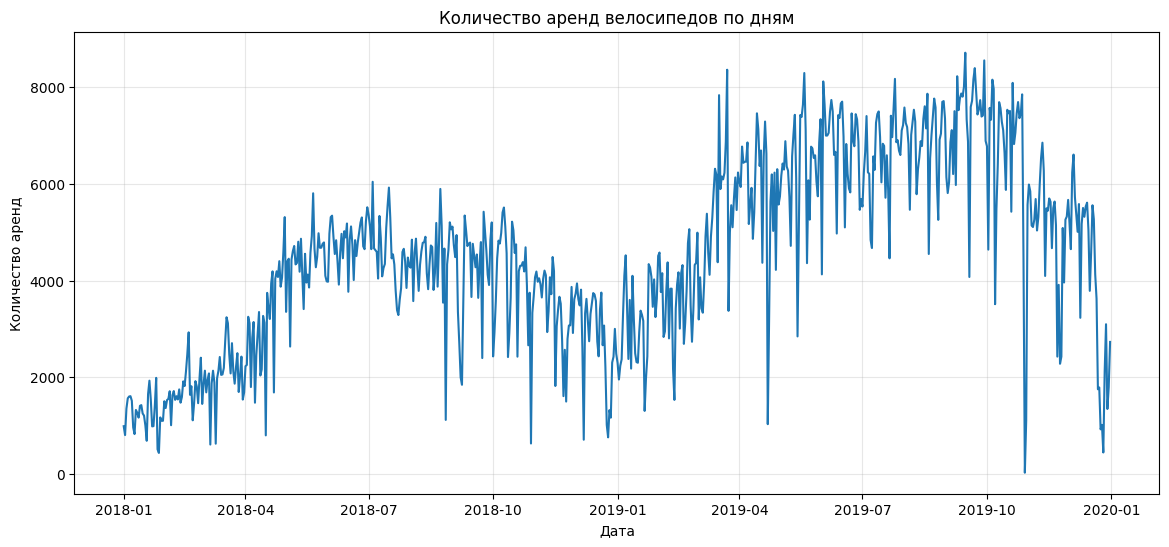

In [158]:
plt.figure(figsize=(14, 6))

plt.plot(df['dteday'], df['cnt'])

plt.title('Количество аренд велосипедов по дням')
plt.xlabel('Дата')
plt.ylabel('Количество аренд')
plt.grid(alpha=0.3)

plt.show()

### Вывод

По графику временного ряда наблюдается общий восходящий тренд: во втором году количество аренд велосипедов в среднем выше, чем в первом.

Также прослеживается годовая сезонность: количество аренд увеличивается в тёплое время года и снижается в холодное. Подобная динамика повторяется в течение обоих лет наблюдений.

На графике присутствуют отдельные резкие падения количества аренд относительно соседних дней, которые можно рассматривать как возможные аномальные наблюдения. Они могут быть связаны с внешними факторами, например погодными условиями или праздниками.

## 2. Формирование признаков

Для сведения задачи прогнозирования временного ряда к задаче регрессии сформируем дополнительные признаки. Все признаки должны быть доступны на момент построения прогноза, чтобы исключить утечку информации из будущего.

### Календарные признаки
Сначала сформируем календарные признаки на основе даты наблюдения:
 - день недели
 - месяц
 - год 
 - признак выходного дня
 
  Информация о праздничных днях уже содержится в исходном датасете в столбце holiday.
  Поскольку временной ряд имеет дневную частоту, признак часа не используется.

In [159]:
df['day_of_week'] = df['dteday'].dt.dayofweek
df['month'] = df['dteday'].dt.month
df['year'] = df['dteday'].dt.year

df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)

### Лаговые признаки

Для учёта зависимости текущего значения временного ряда от предыдущих наблюдений сформируем лаговые признаки.

Будем использовать значения количества аренд за предыдущие 7 дней: от lag_1 до lag_7. Таким образом, при прогнозировании значения в момент времени t модель использует только значения целевой переменной, наблюдавшиеся ранее.

In [160]:
for lag in range(1, 8):
    df[f'lag_{lag}'] = df['cnt'].shift(lag)

Проверим корректность формирования лагов на первых наблюдениях временного ряда.
В первых строках присутствуют пропущенные значения, поскольку для них отсутствует необходимое количество предыдущих наблюдений. Начиная с восьмого наблюдения доступны значения всех лагов от lag_1 до lag_7.

In [161]:
df[['dteday', 'cnt', 'lag_1', 'lag_2', 'lag_3',
    'lag_4', 'lag_5', 'lag_6', 'lag_7']].head(10)

,dteday,cnt,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7
0,2018-01-01,985,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2018-01-02,801,985.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2018-01-03,1349,801.0,985.0,NaN,NaN,NaN,NaN,NaN
3,2018-01-04,1562,1349.0,801.0,985.0,NaN,NaN,NaN,NaN
4,2018-01-05,1600,1562.0,1349.0,801.0,985.0,NaN,NaN,NaN
5,2018-01-06,1606,1600.0,1562.0,1349.0,801.0,985.0,NaN,NaN
6,2018-01-07,1510,1606.0,1600.0,1562.0,1349.0,801.0,985.0,NaN
7,2018-01-08,959,1510.0,1606.0,1600.0,1562.0,1349.0,801.0,985.0
8,2018-01-09,822,959.0,1510.0,1606.0,1600.0,1562.0,1349.0,801.0
9,2018-01-10,1321,822.0,959.0,1510.0,1606.0,1600.0,1562.0,1349.0


### Скользящие статистики

Для описания локальной динамики временного ряда сформируем скользящие статистики за предыдущие 7 дней: среднее значение, медиану, стандартное отклонение, минимум и максимум.

Перед вычислением статистик временной ряд сдвигается на один день. Благодаря этому значение cnt текущего дня не участвует в расчёте его признаков, что предотвращает утечку данных из будущего.

In [162]:
past_cnt = df['cnt'].shift(1)

df['rolling_mean_7'] = past_cnt.rolling(window=7).mean()
df['rolling_median_7'] = past_cnt.rolling(window=7).median()
df['rolling_std_7'] = past_cnt.rolling(window=7).std()
df['rolling_min_7'] = past_cnt.rolling(window=7).min()
df['rolling_max_7'] = past_cnt.rolling(window=7).max()

Проверим значения скользящих статистик на первых наблюдениях временного ряда.

Первые 7 наблюдений содержат пропущенные значения скользящих статистик, поскольку для их расчёта недостаточно предыдущих данных. Начиная с восьмого наблюдения статистики рассчитываются по полному окну из 7 предыдущих дней. Текущее значение целевой переменной в расчёт не включается.

In [163]:
df[['dteday', 'cnt',
    'rolling_mean_7',
    'rolling_median_7',
    'rolling_std_7',
    'rolling_min_7',
    'rolling_max_7']].head(10)

,dteday,cnt,rolling_mean_7,rolling_median_7,rolling_std_7,rolling_min_7,rolling_max_7
0,2018-01-01,985,NaN,NaN,NaN,NaN,NaN
1,2018-01-02,801,NaN,NaN,NaN,NaN,NaN
2,2018-01-03,1349,NaN,NaN,NaN,NaN,NaN
3,2018-01-04,1562,NaN,NaN,NaN,NaN,NaN
4,2018-01-05,1600,NaN,NaN,NaN,NaN,NaN
5,2018-01-06,1606,NaN,NaN,NaN,NaN,NaN
6,2018-01-07,1510,NaN,NaN,NaN,NaN,NaN
7,2018-01-08,959,1344.714286,1510.0,324.810568,801.0,1606.0
8,2018-01-09,822,1341.000000,1510.0,329.721094,801.0,1606.0
9,2018-01-10,1321,1344.000000,1510.0,324.035492,822.0,1606.0


### Сезонные признаки

Для учёта сезонности временного ряда используются значения целевой переменной за аналогичные предыдущие периоды.

Значение за предыдущий день уже представлено признаком lag_1, а значение за предыдущую неделю — признаком lag_7. Поскольку при визуальном анализе была обнаружена годовая сезонность, дополнительно сформируем признак количества аренд 365 дней назад.

In [164]:
df['lag_365'] = df['cnt'].shift(365)

Признак lag_365 становится доступен начиная со второго года наблюдений. Например, для 01.01.2019 он содержит значение количества аренд за 01.01.2018. Таким образом, признак позволяет учитывать обнаруженную годовую сезонность без использования информации из будущего.

In [165]:
df[['dteday', 'cnt', 'lag_365']].iloc[360:370]

,dteday,cnt,lag_365
360,2018-12-27,1162,NaN
361,2018-12-28,2302,NaN
362,2018-12-29,2423,NaN
363,2018-12-30,2999,NaN
364,2018-12-31,2485,NaN
365,2019-01-01,2294,985.0
366,2019-01-02,1951,801.0
367,2019-01-03,2236,1349.0
368,2019-01-04,2368,1562.0
369,2019-01-05,3272,1600.0


### Подготовка сформированных признаков

После создания лаговых, скользящих и сезонных признаков в первых наблюдениях временного ряда появились пропущенные значения. Они возникают естественным образом, поскольку для первых дат отсутствует необходимая история наблюдений.

Проверим количество пропущенных значений в сформированных признаках перед подготовкой данных к моделированию.

In [166]:
feature_columns = [
    'day_of_week', 'month', 'year', 'is_weekend', 'holiday',
    'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7',
    'rolling_mean_7', 'rolling_median_7', 'rolling_std_7',
    'rolling_min_7', 'rolling_max_7',
    'lag_365'
]

df[feature_columns].isna().sum()

day_of_week           0
month                 0
year                  0
is_weekend            0
holiday               0
lag_1                 1
lag_2                 2
lag_3                 3
lag_4                 4
lag_5                 5
lag_6                 6
lag_7                 7
rolling_mean_7        7
rolling_median_7      7
rolling_std_7         7
rolling_min_7         7
rolling_max_7         7
lag_365             365
dtype: int64

Пропущенные значения в сформированных признаках связаны с отсутствием необходимой истории наблюдений. Наибольшее количество пропусков содержит сезонный признак lag_365, поэтому для дальнейшего моделирования используются только наблюдения, для которых доступны значения всех сформированных признаков.

Пропуски не заполняются искусственно, так как это могло бы исказить временную структуру данных.

In [167]:
df_model = df.dropna(subset=feature_columns).copy()

print('Размер исходного датасета:', df.shape)
print('Размер данных после формирования признаков:', df_model.shape)

print('\nПериод данных для моделирования:')
print('Начало:', df_model['dteday'].min())
print('Конец:', df_model['dteday'].max())

Размер исходного датасета: (730, 33)
Размер данных после формирования признаков: (365, 33)

Период данных для моделирования:
Начало: 2019-01-01 00:00:00
Конец: 2019-12-31 00:00:00


В результате были сформированы календарные, лаговые, скользящие и сезонные признаки. Все признаки, основанные на целевой переменной, рассчитывались только по предыдущим наблюдениям, что исключает утечку данных из будущего.

Из-за использования годового сезонного лага lag_365 для моделирования доступны 365 наблюдений за период с 01.01.2019 по 31.12.2019. Наблюдения за 2018 год используются в качестве исторических данных для формирования признаков.

## 3. Разделение данных и кросс-валидация

В задачах прогнозирования временных рядов данные нельзя случайным образом перемешивать при разделении на обучающую и тестовую выборки, поскольку это может привести к использованию будущих наблюдений для прогнозирования прошлого.

Поэтому данные разделяются в хронологическом порядке: первые 80% наблюдений используются в качестве обучающей выборки (train), а последние 20% — в качестве тестовой (test).

In [168]:
split_index = int(len(df_model) * 0.8)

train = df_model.iloc[:split_index].copy()
test = df_model.iloc[split_index:].copy()

print('Размер train:', train.shape)
print('Размер test:', test.shape)

print('\nПериод train:')
print(train['dteday'].min(), '—', train['dteday'].max())

print('\nПериод test:')
print(test['dteday'].min(), '—', test['dteday'].max())

Размер train: (292, 33)
Размер test: (73, 33)

Период train:
2019-01-01 00:00:00 — 2019-10-19 00:00:00

Период test:
2019-10-20 00:00:00 — 2019-12-31 00:00:00


### Формирование обучающей и тестовой выборок

В качестве целевой переменной используется cnt — количество аренд велосипедов за день. В матрицу признаков включаются ранее сформированные календарные, лаговые, скользящие и сезонные признаки.

Обучающая и тестовая выборки формируются с сохранением временного порядка данных.

In [169]:
X_train = train[feature_columns]
y_train = train['cnt']

X_test = test[feature_columns]
y_test = test['cnt']

print('X_train:', X_train.shape)
print('y_train:', y_train.shape)

print('X_test:', X_test.shape)
print('y_test:', y_test.shape)

X_train: (292, 18)
y_train: (292,)
X_test: (73, 18)
y_test: (73,)


### Кросс-валидация временного ряда

Для оценки модели на обучающей выборке применяется кросс-валидация с расширяющимся окном. В отличие от обычной кросс-валидации, порядок наблюдений не нарушается: модель на каждом шаге обучается на более ранних данных и проверяется на последующем временном интервале.

Для реализации используется TimeSeriesSplit. Тестовая выборка при кросс-валидации не используется и остаётся полностью отложенной для итоговой оценки модели.

In [170]:
tscv = TimeSeriesSplit(n_splits=5)

for i, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):
    print(f'Разбиение {i}:')
    print(f'  Train: {len(train_idx)} наблюдений '
          f'({train.iloc[train_idx[0]]["dteday"].date()} — '
          f'{train.iloc[train_idx[-1]]["dteday"].date()})')
    
    print(f'  Validation: {len(val_idx)} наблюдений '
          f'({train.iloc[val_idx[0]]["dteday"].date()} — '
          f'{train.iloc[val_idx[-1]]["dteday"].date()})')
    print()

Разбиение 1:
  Train: 52 наблюдений (2019-01-01 — 2019-02-21)
  Validation: 48 наблюдений (2019-02-22 — 2019-04-10)

Разбиение 2:
  Train: 100 наблюдений (2019-01-01 — 2019-04-10)
  Validation: 48 наблюдений (2019-04-11 — 2019-05-28)

Разбиение 3:
  Train: 148 наблюдений (2019-01-01 — 2019-05-28)
  Validation: 48 наблюдений (2019-05-29 — 2019-07-15)

Разбиение 4:
  Train: 196 наблюдений (2019-01-01 — 2019-07-15)
  Validation: 48 наблюдений (2019-07-16 — 2019-09-01)

Разбиение 5:
  Train: 244 наблюдений (2019-01-01 — 2019-09-01)
  Validation: 48 наблюдений (2019-09-02 — 2019-10-19)



В результате сформировано 5 последовательных разбиений с расширяющимся обучающим окном. На каждом шаге валидационный период расположен строго после обучающего, что соответствует требованиям к кросс-валидации временных рядов.

Размер обучающей выборки постепенно увеличивается от 52 до 244 наблюдений, а размер валидационной выборки составляет 48 наблюдений. Отложенная тестовая выборка при кросс-валидации не используется.

## 4. Построение модели прогнозирования

Для прогнозирования временного ряда используется модель **Ridge-регрессии**.

Ridge представляет собой линейную регрессию с L2-регуляризацией. В данной работе модель использует большое количество взаимосвязанных признаков: лаговые значения lag_1–lag_7, скользящие статистики и сезонный признак lag_365. Между такими признаками может существовать сильная корреляция, что способно приводить к нестабильности коэффициентов обычной линейной регрессии.

Ridge-регрессия добавляет штраф за слишком большие значения коэффициентов модели, что позволяет уменьшить влияние мультиколлинеарности и повысить устойчивость модели.

Кроме того, Ridge сохраняет простоту и интерпретируемость линейной модели, поэтому хорошо подходит для базового решения задачи прогнозирования временного ряда методом сведения к регрессии.

### Подбор коэффициента регуляризации

Для обучения Ridge-регрессии необходимо выполнить стандартизацию признаков, поскольку они имеют различные масштабы, а используемая в модели L2-регуляризация чувствительна к масштабу входных данных. Для стандартизации используется StandardScaler.

Масштабирование и Ridge-регрессия объединяются в единый Pipeline. Это позволяет выполнять стандартизацию отдельно на каждом разбиении временной кросс-валидации: параметры StandardScaler рассчитываются только по обучающей части, после чего применяются к соответствующей валидационной части. Таким образом предотвращается утечка информации из будущих наблюдений.

Основным гиперпараметром Ridge-регрессии является коэффициент alpha, определяющий силу L2-регуляризации. Чем больше значение alpha, тем сильнее ограничиваются коэффициенты модели. Для выбора оптимального значения alpha проверим несколько его значений с использованием ранее созданной кросс-валидации TimeSeriesSplit.

In [171]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])


param_grid = {
    'ridge__alpha': [0.01, 0.1, 1, 10, 100, 200, 500, 1000]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_squared_error'
)

grid_search.fit(X_train, y_train)

print('Лучшее значение alpha:', grid_search.best_params_['ridge__alpha'])
print('Среднее MSE на кросс-валидации:', -grid_search.best_score_)

Лучшее значение alpha: 100
Среднее MSE на кросс-валидации: 1343238.366401399


По результатам временной кросс-валидации оптимальным значением коэффициента регуляризации оказалось alpha = 100. Среднее значение MSE на валидационных интервалах составило 1 343 238.37.

### Получение оптимальной модели

In [172]:
best_model = grid_search.best_estimator_

print(best_model)

Pipeline(steps=[('scaler', StandardScaler()), ('ridge', Ridge(alpha=100))])


### Построение прогнозов на тестовой выборке

In [173]:
y_pred = best_model.predict(X_test)

print('Количество фактических значений:', len(y_test))
print('Количество прогнозов:', len(y_pred))

Количество фактических значений: 73
Количество прогнозов: 73


С помощью обученной Ridge-регрессии выполнен прогноз целевой переменной cnt для тестового периода. Для каждого наблюдения прогноз строится на один шаг вперёд с использованием доступных на этот момент лаговых, скользящих, календарных и сезонных признаков.

Для визуальной оценки качества прогноза сравним предсказанные значения с фактическим количеством аренд.

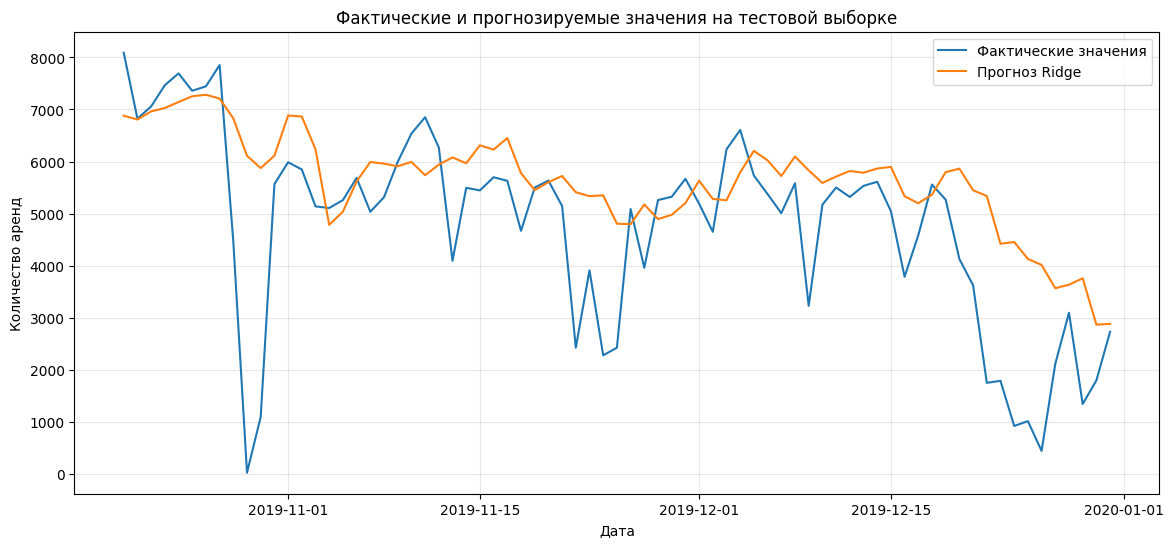

In [174]:
plt.figure(figsize=(14, 6))

plt.plot(test['dteday'], y_test.values, label='Фактические значения')
plt.plot(test['dteday'], y_pred, label='Прогноз Ridge')

plt.title('Фактические и прогнозируемые значения на тестовой выборке')
plt.xlabel('Дата')
plt.ylabel('Количество аренд')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

По графику видно, что Ridge-регрессия в целом воспроизводит общую динамику количества аренд, однако прогноз является более сглаженным по сравнению с фактическим временным рядом.

Наибольшие расхождения наблюдаются в периоды резких падений количества аренд. Модель не полностью воспроизводит такие изменения и, как правило, завышает прогноз при аномально низких фактических значениях. 

### Прогноз на горизонт H шагов вперёд

Для построения многошагового прогноза используется рекурсивная стратегия с горизонтом H = 7 дней.

Прогноз строится для первых семи дней тестового периода. Модель обучена на наблюдениях до 19.10.2019, поэтому значения целевой переменной тестового периода при формировании прогноза не используются.

Сначала рассчитывается прогноз на первый день. Полученное предсказание добавляется к известной истории временного ряда и используется при формировании лаговых и скользящих признаков следующего дня. Процесс последовательно повторяется для всех семи шагов прогнозирования.

Календарные признаки известны заранее, а сезонный признак lag_365 формируется по фактическим значениям, наблюдавшимся 365 дней назад.

Зададим горизонт и даты, которые собираемся прогнозировать

In [175]:
H = 7

forecast_dates = test['dteday'].iloc[:H]

print('Горизонт прогнозирования:', H, 'дней')
print('Начало прогноза:', forecast_dates.iloc[0].date())
print('Конец прогноза:', forecast_dates.iloc[-1].date())

Горизонт прогнозирования: 7 дней
Начало прогноза: 2019-10-20
Конец прогноза: 2019-10-26


#### Подготовка истории для рекурсивного прогноза

Для формирования лаговых и скользящих признаков создадим историю значений целевой переменной, доступную на момент начала прогнозирования.

В историю включаются только фактические значения cnt до начала тестового периода. В дальнейшем после каждого шага рекурсивного прогнозирования история будет дополняться полученным прогнозом, а не фактическим значением тестового периода.

In [176]:
forecast_start = forecast_dates.iloc[0]

history = df.loc[
    df['dteday'] < forecast_start,
    ['dteday', 'cnt']
].copy()

print('Последняя известная дата:', history['dteday'].iloc[-1].date())
print('Последнее известное значение cnt:', history['cnt'].iloc[-1])
print('Количество известных наблюдений:', len(history))

Последняя известная дата: 2019-10-19
Последнее известное значение cnt: 5424
Количество известных наблюдений: 657


#### Формирование признаков для первого шага прогноза

Для первого прогнозируемого дня сформируем тот же набор признаков, который использовался при обучении модели. Календарные признаки определяются по дате, а лаговые и скользящие признаки рассчитываются по известной истории временного ряда.

In [177]:
current_date = forecast_dates.iloc[0]

last_values = history['cnt']

first_step = {
    'day_of_week': current_date.dayofweek,
    'month': current_date.month,
    'year': current_date.year,
    'is_weekend': int(current_date.dayofweek >= 5),
    'holiday': test.loc[test['dteday'] == current_date, 'holiday'].iloc[0],

    'lag_1': last_values.iloc[-1],
    'lag_2': last_values.iloc[-2],
    'lag_3': last_values.iloc[-3],
    'lag_4': last_values.iloc[-4],
    'lag_5': last_values.iloc[-5],
    'lag_6': last_values.iloc[-6],
    'lag_7': last_values.iloc[-7],

    'rolling_mean_7': last_values.iloc[-7:].mean(),
    'rolling_median_7': last_values.iloc[-7:].median(),
    'rolling_std_7': last_values.iloc[-7:].std(),
    'rolling_min_7': last_values.iloc[-7:].min(),
    'rolling_max_7': last_values.iloc[-7:].max(),

    'lag_365': df.loc[
        df['dteday'] == current_date - pd.Timedelta(days=365),
        'cnt'
    ].iloc[0]
}

X_first_step = pd.DataFrame([first_step])[feature_columns]

X_first_step

,day_of_week,month,year,is_weekend,holiday,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,rolling_mean_7,rolling_median_7,rolling_std_7,rolling_min_7,rolling_max_7,lag_365
0,6,10,2019,1,0,5424,7509,7461,7534,5875,6639,7109,6793.0,7109.0,851.314474,5424,7534,4195


Первый рекурсивный прогноз

In [178]:
first_prediction = best_model.predict(X_first_step)[0]

print('Дата прогноза:', current_date.date())
print('Прогноз cnt:', round(first_prediction, 2))

Дата прогноза: 2019-10-20
Прогноз cnt: 6879.49


#### Рекурсивное прогнозирование

После проверки первого шага выполним прогноз последовательно для всего горизонта H = 7.

На каждом шаге заново формируются календарные, лаговые, скользящие и сезонные признаки. Полученное прогнозное значение cnt добавляется в историю и используется вместо неизвестного фактического значения при прогнозировании следующего дня.

In [179]:
history_recursive = df.loc[
    df['dteday'] < forecast_start,
    ['dteday', 'cnt']
].copy()

recursive_predictions = []

for current_date in forecast_dates:

    last_values = history_recursive['cnt']

    features = {
        'day_of_week': current_date.dayofweek,
        'month': current_date.month,
        'year': current_date.year,
        'is_weekend': int(current_date.dayofweek >= 5),
        'holiday': test.loc[
            test['dteday'] == current_date, 'holiday'
        ].iloc[0],

        'lag_1': last_values.iloc[-1],
        'lag_2': last_values.iloc[-2],
        'lag_3': last_values.iloc[-3],
        'lag_4': last_values.iloc[-4],
        'lag_5': last_values.iloc[-5],
        'lag_6': last_values.iloc[-6],
        'lag_7': last_values.iloc[-7],

        'rolling_mean_7': last_values.iloc[-7:].mean(),
        'rolling_median_7': last_values.iloc[-7:].median(),
        'rolling_std_7': last_values.iloc[-7:].std(),
        'rolling_min_7': last_values.iloc[-7:].min(),
        'rolling_max_7': last_values.iloc[-7:].max(),

        'lag_365': df.loc[
            df['dteday'] == current_date - pd.Timedelta(days=365),
            'cnt'
        ].iloc[0]
    }

    X_current = pd.DataFrame([features])[feature_columns]

    prediction = best_model.predict(X_current)[0]

    recursive_predictions.append(prediction)

    new_row = pd.DataFrame({
        'dteday': [current_date],
        'cnt': [prediction]
    })

    history_recursive = pd.concat(
        [history_recursive, new_row],
        ignore_index=True
    )

In [180]:
recursive_result = pd.DataFrame({
    'Дата': forecast_dates.values,
    'Фактическое значение': y_test.iloc[:H].values,
    'Рекурсивный прогноз': recursive_predictions
})

recursive_result

,Дата,Фактическое значение,Рекурсивный прогноз
0,2019-10-20,8090,6879.492666
1,2019-10-21,6824,6473.705666
2,2019-10-22,7058,6727.962850
3,2019-10-23,7466,6846.952571
4,2019-10-24,7693,6851.047817
5,2019-10-25,7359,6841.887487
6,2019-10-26,7444,6758.610145


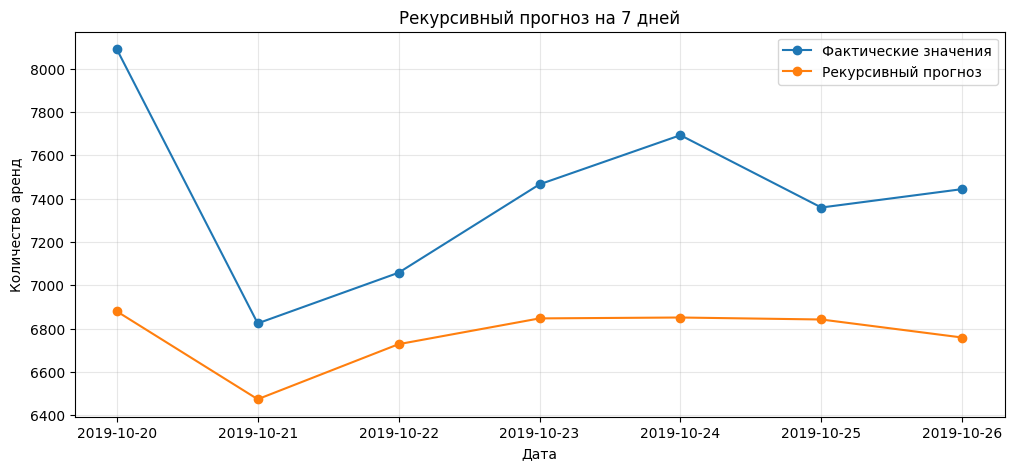

In [181]:
plt.figure(figsize=(12, 5))

plt.plot(
    recursive_result['Дата'],
    recursive_result['Фактическое значение'],
    marker='o',
    label='Фактические значения'
)

plt.plot(
    recursive_result['Дата'],
    recursive_result['Рекурсивный прогноз'],
    marker='o',
    label='Рекурсивный прогноз'
)

plt.title('Рекурсивный прогноз на 7 дней')
plt.xlabel('Дата')
plt.ylabel('Количество аренд')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

В результате был построен рекурсивный прогноз на горизонт 7 дней. Для первого шага использовались только известные фактические значения временного ряда, а на последующих шагах ранее полученные прогнозы последовательно использовались при формировании лаговых и скользящих признаков.

Полученный прогноз является более сглаженным по сравнению с фактическими значениями. При рекурсивной стратегии ошибка предыдущих прогнозов может передаваться на последующие шаги, поскольку предсказанные значения используются моделью в качестве части входных данных.

## 5. Оценка качества прогнозирования

Для оценки качества модели рассчитаем метрики MSE, MAE, MAPE и WAPE на обучающей и тестовой выборках.

- MSE (Mean Squared Error) — средний квадрат ошибки. Сильнее реагирует на крупные ошибки прогноза.
- MAE (Mean Absolute Error) — средняя абсолютная ошибка прогноза в единицах целевой переменной.
- MAPE (Mean Absolute Percentage Error) — средняя абсолютная ошибка в процентах относительно фактических значений.
- WAPE (Weighted Absolute Percentage Error) — отношение суммы абсолютных ошибок к сумме фактических значений. В отличие от MAPE, метрика менее чувствительна к отдельным очень малым значениям целевой переменной.

Сравнение метрик на обучающей и тестовой выборках позволит оценить способность модели обобщать закономерности временного ряда на более поздний период.

In [182]:
y_train_pred = best_model.predict(X_train)

In [183]:
def calculate_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    
    mape = np.mean(
        np.abs((np.array(y_true) - np.array(y_pred)) / np.array(y_true))
    ) * 100
    
    wape = (
        np.sum(np.abs(np.array(y_true) - np.array(y_pred)))
        / np.sum(np.abs(np.array(y_true)))
    ) * 100
    
    return mse, mae, mape, wape


train_metrics = calculate_metrics(y_train, y_train_pred)
test_metrics = calculate_metrics(y_test, y_pred)

metrics_table = pd.DataFrame({
    'Выборка': ['Train', 'Test'],
    'MSE': [train_metrics[0], test_metrics[0]],
    'MAE': [train_metrics[1], test_metrics[1]],
    'MAPE, %': [train_metrics[2], test_metrics[2]],
    'WAPE, %': [train_metrics[3], test_metrics[3]]
})

metrics_table.round(2)

,Выборка,MSE,MAE,"MAPE, %","WAPE, %"
0,Train,881685.03,693.33,15.73,11.91
1,Test,2674439.27,1124.70,431.35,23.64


### Сравнение качества на обучающей и тестовой выборках

На обучающей выборке модель показывает меньшую ошибку, чем на тестовой. MAE увеличивается с 693.33 до 1124.70, а WAPE — с 11.91% до 23.64%. Значение MSE также существенно возрастает на тестовой выборке.

Особенно большое значение на тестовой выборке принимает MAPE — 431.35%. Это связано с наличием наблюдений с очень малым фактическим количеством аренд. Поскольку MAPE рассчитывает ошибку относительно каждого фактического значения, значения, близкие к нулю, приводят к резкому увеличению процентной ошибки.

Поэтому для данного временного ряда WAPE является более устойчивой и интерпретируемой процентной метрикой. На тестовом периоде суммарная абсолютная ошибка составляет около 23.64% от суммарного фактического количества аренд.

### Анализ ошибок прогнозирования

Для определения периодов, в которых модель допускает наибольшие ошибки, построим графики фактических и прогнозируемых значений, а также абсолютной ошибки прогноза. Это позволит оценить, насколько точно модель отражает тренд и сезонность временного ряда, и выявить резкие изменения, при которых качество прогноза снижается.

In [184]:
error_analysis = pd.DataFrame({
    'Дата': test['dteday'].values,
    'Фактическое значение': y_test.values,
    'Прогноз': y_pred
})

error_analysis['Абсолютная ошибка'] = np.abs(
    error_analysis['Фактическое значение'] - error_analysis['Прогноз']
)

error_analysis = error_analysis.sort_values(
    'Абсолютная ошибка',
    ascending=False
)

error_analysis.head(10)

,Дата,Фактическое значение,Прогноз,Абсолютная ошибка
9,2019-10-29,22,6109.147422,6087.147422
10,2019-10-30,1096,5874.186556,4778.186556
63,2019-12-22,1749,5337.055667,3588.055667
67,2019-12-26,441,4013.534233,3572.534233
65,2019-12-24,920,4453.673676,3533.673676
66,2019-12-25,1013,4129.106442,3116.106442
35,2019-11-24,2277,5349.825694,3072.825694
33,2019-11-22,2425,5410.198030,2985.198030
64,2019-12-23,1787,4420.347524,2633.347524
50,2019-12-09,3228,5829.824535,2601.824535


### График абсолютной ошибки

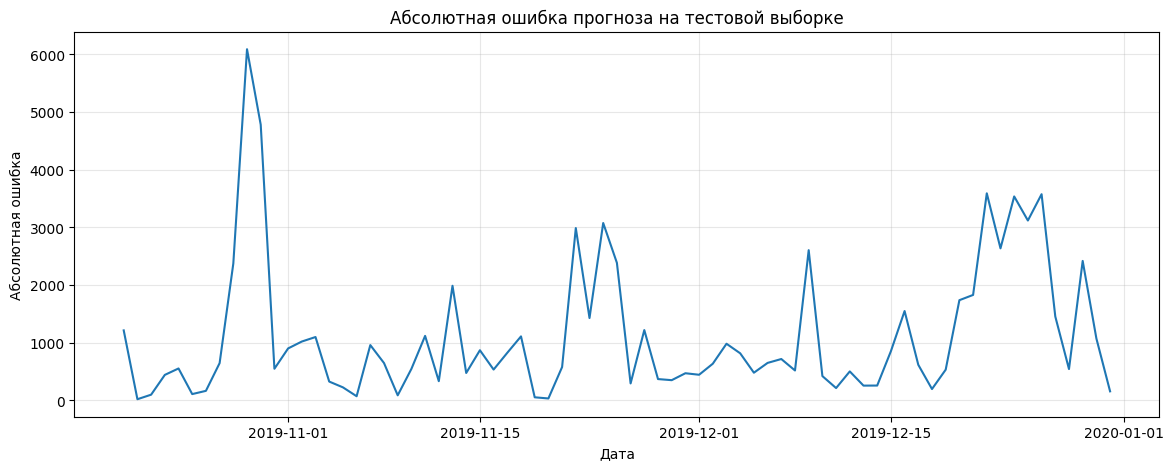

In [185]:
error_plot = error_analysis.sort_values('Дата')

plt.figure(figsize=(14, 5))

plt.plot(
    error_plot['Дата'],
    error_plot['Абсолютная ошибка']
)

plt.title('Абсолютная ошибка прогноза на тестовой выборке')
plt.xlabel('Дата')
plt.ylabel('Абсолютная ошибка')
plt.grid(alpha=0.3)

plt.show()

### Фактические и прогнозируемые значения количества аренд велосипедов на тестовой выборке

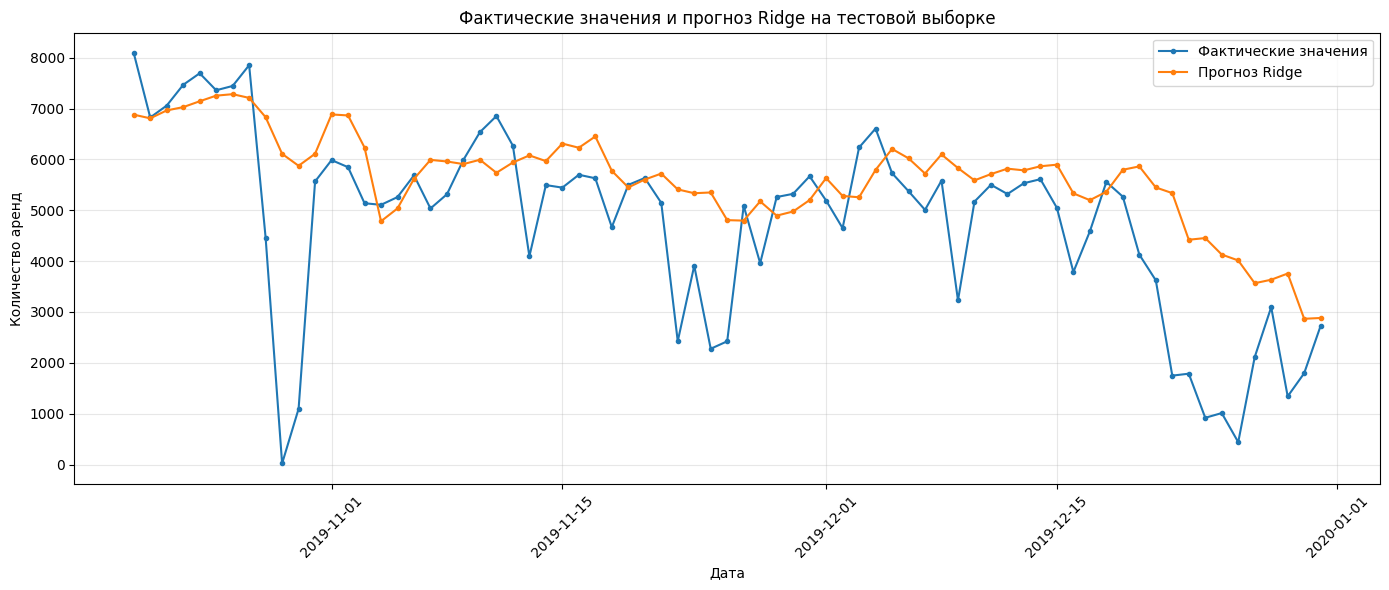

In [186]:
plt.figure(figsize=(14, 6))

plt.plot(
    test['dteday'],
    y_test,
    label='Фактические значения',
    marker='o',
    markersize=3
)

plt.plot(
    test['dteday'],
    y_pred,
    label='Прогноз Ridge',
    marker='o',
    markersize=3
)

plt.title('Фактические значения и прогноз Ridge на тестовой выборке')
plt.xlabel('Дата')
plt.ylabel('Количество аренд')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Вывод

- Тренд. Модель отражает общую динамику количества аренд, но не всегда точно предсказывает резкие изменения.

- Сезонность. В конце года модель завышает прогноз относительно фактических значений. Однако тестового периода недостаточно для полноценной оценки годовой сезонности.

- Выбросы и резкие изменения. Наибольшие ошибки возникают при резком снижении спроса. Самая большая ошибка наблюдается 29 октября: фактически 22 аренды, прогноз — около 6109.

Модель лучше отражает общую динамику, чем резкие локальные изменения. Наибольшие ошибки связаны с резкими падениями спроса и его снижением в конце года.

## 6. STL-декомпозиция временного ряда

STL позволяет представить исходный временной ряд в виде трёх основных компонентов:

- тренд — долгосрочное направление изменения временного ряда;
- сезонная компонента — регулярно повторяющиеся колебания;
- остаточная компонента — изменения, которые не объясняются трендом и сезонностью.

Поскольку данные представлены ежедневными наблюдениями, для анализа недельной сезонности используется период, равный 7 дням. Это позволяет исследовать повторяющиеся колебания спроса в течение недели.

In [187]:
stl = STL(
    df['cnt'],
    period=7,
    robust=True
)

stl_result = stl.fit()

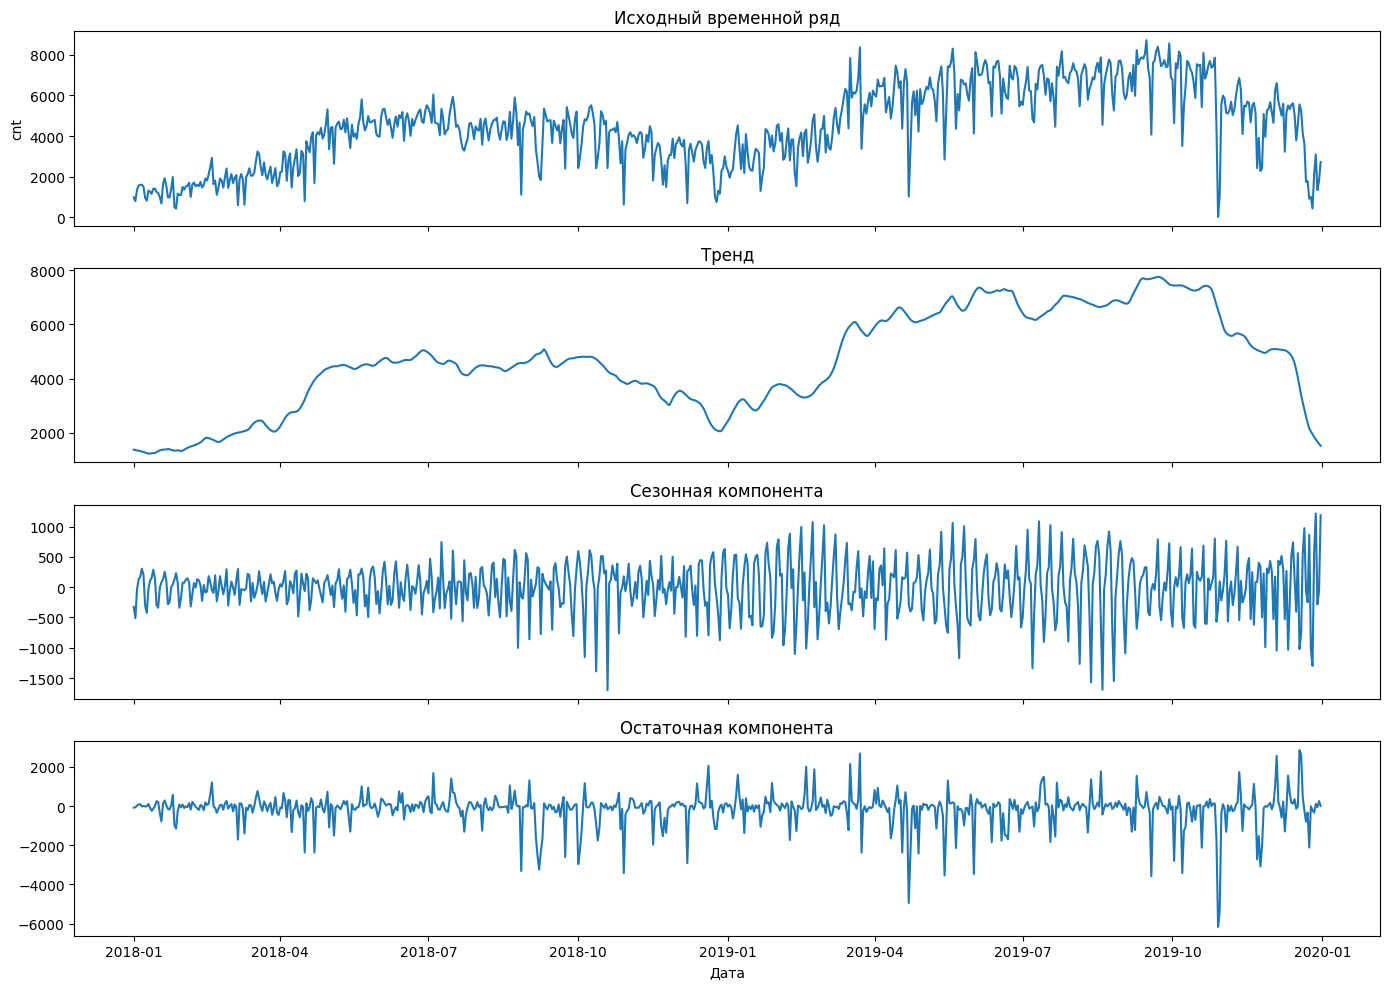

In [188]:
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

axes[0].plot(df['dteday'], df['cnt'])
axes[0].set_title('Исходный временной ряд')
axes[0].set_ylabel('cnt')

axes[1].plot(df['dteday'], stl_result.trend)
axes[1].set_title('Тренд')

axes[2].plot(df['dteday'], stl_result.seasonal)
axes[2].set_title('Сезонная компонента')

axes[3].plot(df['dteday'], stl_result.resid)
axes[3].set_title('Остаточная компонента')
axes[3].set_xlabel('Дата')

plt.tight_layout()
plt.show()

### Анализ STL-декомпозиции

STL-декомпозиция позволяет выделить основные составляющие временного ряда. 

Тренд показывает, что количество аренд велосипедов увеличивалось с начала 2018 года до большей части 2019 года, после чего наблюдается снижение, особенно заметное в конце 2019 года.

Сезонная компонента отражает повторяющиеся колебания с периодом 7 дней, которые могут быть связаны с различиями в спросе по дням недели. 

Остаточная компонента содержит отдельные значительные отклонения, не объясняемые выделенными трендом и сезонностью.

### Проверка влияния признаков на основе компонентов декомпозиции

Для оценки влияния компонентов STL-декомпозиции на качество прогнозирования сформируем дополнительные признаки на основе исторических данных.

При прогнозировании значение целевой переменной текущего дня неизвестно. Поэтому для каждой даты компоненты STL рассчитываются только по наблюдениям, предшествующим этой дате. Из полученных результатов используются значения компонентов на последнем доступном дне.

Будут сформированы три дополнительных признака:

- stl_trend_lag1 — значение трендовой компоненты на предыдущем доступном дне;
- stl_seasonal_lag1 — значение сезонной компоненты на предыдущем доступном дне;
- stl_resid_lag1 — значение остаточной компоненты на предыдущем доступном дне.

Для декомпозиции используется недельный период, равный 7 дням. После формирования признаков можно будет сравнить качество модели с исходным набором признаков и с расширенным набором, включающим компоненты STL.


In [189]:
def create_stl_features(data, dates, period=7):
    stl_features = []

    for current_date in dates:
        history = data.loc[
            data['dteday'] < current_date,
            'cnt'
        ]

        stl_result_past = STL(
            history,
            period=period,
            robust=True
        ).fit()

        stl_features.append({
            'dteday': current_date,
            'stl_trend_lag1': stl_result_past.trend.iloc[-1],
            'stl_seasonal_lag1': stl_result_past.seasonal.iloc[-1],
            'stl_resid_lag1': stl_result_past.resid.iloc[-1]
        })

    return pd.DataFrame(stl_features)

### Создание STL-признаков

Для прогнозирования формируются три признака на основе STL-декомпозиции: тренд, сезонная и остаточная компоненты. Используется недельный период 7, а расчёт выполняется только по прошлым наблюдениям, чтобы избежать утечки будущих данных.

In [190]:
stl_features = create_stl_features(
    data=df,
    dates=df_model['dteday'],
    period=7
)

stl_features.head(10)

,dteday,stl_trend_lag1,stl_seasonal_lag1,stl_resid_lag1
0,2019-01-01,1734.807151,620.571448,129.621401
1,2019-01-02,2016.011668,167.609508,110.378825
2,2019-01-03,2473.239387,-651.721772,129.482385
3,2019-01-04,2813.256033,-625.847585,48.591552
4,2019-01-05,2744.816667,-137.834867,-238.981800
5,2019-01-06,2781.225542,545.440575,-54.666116
6,2019-01-07,2961.431910,1078.734102,57.833988
7,2019-01-08,3328.622170,1020.554837,171.822993
8,2019-01-09,3519.595121,-77.921111,-16.674009
9,2019-01-10,3613.270344,-1153.477984,-83.792360


Полученные STL-признаки объединим с исходным набором данных по дате. В результате к исходным 18 признакам добавятся три признака, отражающие трендовую, сезонную и остаточную компоненты.

In [191]:
df_model_stl = df_model.merge(
    stl_features,
    on='dteday',
    how='left'
)

stl_feature_columns = feature_columns + [
    'stl_trend_lag1',
    'stl_seasonal_lag1',
    'stl_resid_lag1'
]

print('Количество исходных признаков:', len(feature_columns))
print('Количество признаков после добавления STL:', len(stl_feature_columns))

df_model_stl[
    ['dteday', 'cnt',
     'stl_trend_lag1',
     'stl_seasonal_lag1',
     'stl_resid_lag1']
].head()

Количество исходных признаков: 18
Количество признаков после добавления STL: 21


,dteday,cnt,stl_trend_lag1,stl_seasonal_lag1,stl_resid_lag1
0,2019-01-01,2294,1734.807151,620.571448,129.621401
1,2019-01-02,1951,2016.011668,167.609508,110.378825
2,2019-01-03,2236,2473.239387,-651.721772,129.482385
3,2019-01-04,2368,2813.256033,-625.847585,48.591552
4,2019-01-05,3272,2744.816667,-137.834867,-238.981800


In [192]:
print(
    'Количество пропусков в признаках:',
    df_model_stl[stl_feature_columns].isna().sum().sum()
)

Количество пропусков в признаках: 0


### Разделение данных

Для модели с дополнительными STL-признаками используется то же временное разделение на обучающую и тестовую выборки, что и для исходной модели. 

In [193]:
train_stl = df_model_stl.iloc[:split_index].copy()
test_stl = df_model_stl.iloc[split_index:].copy()

X_train_stl = train_stl[stl_feature_columns]
y_train_stl = train_stl['cnt']

X_test_stl = test_stl[stl_feature_columns]
y_test_stl = test_stl['cnt']

print('Train:', X_train_stl.shape)
print('Test:', X_test_stl.shape)

print('\nПериод Train:')
print(train_stl['dteday'].min(), '—', train_stl['dteday'].max())

print('\nПериод Test:')
print(test_stl['dteday'].min(), '—', test_stl['dteday'].max())

Train: (292, 21)
Test: (73, 21)

Период Train:
2019-01-01 00:00:00 — 2019-10-19 00:00:00

Период Test:
2019-10-20 00:00:00 — 2019-12-31 00:00:00


#### Обучение Ridge-регрессии с STL-признаками

Для оценки влияния новых признаков повторно обучим Ridge-регрессию. Используем тот же Pipeline, временную кросс-валидацию TimeSeriesSplit и набор значений alpha, что и для исходной модели.

Это позволяет сравнивать модели в одинаковых условиях, изменяя только состав входных признаков.

In [194]:
pipeline_stl = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])

param_grid_stl = {
    'ridge__alpha': [0.01, 0.1, 1, 10, 100, 200, 500, 1000]
}

grid_search_stl = GridSearchCV(
    estimator=pipeline_stl,
    param_grid=param_grid_stl,
    cv=tscv,
    scoring='neg_mean_squared_error'
)

grid_search_stl.fit(X_train_stl, y_train_stl)

print(
    'Лучшее значение alpha:',
    grid_search_stl.best_params_['ridge__alpha']
)

print(
    'Среднее MSE на кросс-валидации:',
    -grid_search_stl.best_score_
)

Лучшее значение alpha: 100
Среднее MSE на кросс-валидации: 1317924.497255002


### Прогноз на тестовой выборке

Используем лучшую модель, найденную при временной кросс-валидации, для прогнозирования значений целевой переменной на тестовой выборке.

In [195]:
best_model_stl = grid_search_stl.best_estimator_

y_pred_stl = best_model_stl.predict(X_test_stl)

print('Количество прогнозов:', len(y_pred_stl))

Количество прогнозов: 73


In [196]:
y_pred_train_stl = best_model_stl.predict(X_train_stl)

stl_train_metrics = calculate_metrics(
    y_train_stl,
    y_pred_train_stl
)

stl_test_metrics = calculate_metrics(
    y_test_stl,
    y_pred_stl
)
print('Метрики на Train:')
print('MSE:', stl_train_metrics[0])
print('MAE:', stl_train_metrics[1])
print('MAPE, %:', stl_train_metrics[2])
print('WAPE, %:', stl_train_metrics[3])

print('\nМетрики на Test:')
print('MSE:', stl_test_metrics[0])
print('MAE:', stl_test_metrics[1])
print('MAPE, %:', stl_test_metrics[2])
print('WAPE, %:', stl_test_metrics[3])

Метрики на Train:
MSE: 871859.8877205928
MAE: 682.2181984467315
MAPE, %: 15.517132811515797
WAPE, %: 11.71509624275454

Метрики на Test:
MSE: 2518502.6871395637
MAE: 1092.6868819170768
MAPE, %: 418.71884505708607
WAPE, %: 22.967107501726606


#### Сравнение качества моделей

Для оценки влияния признаков на основе компонентов STL-декомпозиции сравним метрики исходной Ridge-регрессии и модели, обученной с дополнительными STL-признаками.

In [197]:

comparison_table = pd.DataFrame({
    'Модель': ['Ridge', 'Ridge + STL'],

    'Train MSE': [
        train_metrics[0],
        stl_train_metrics[0]
    ],
    'Test MSE': [
        test_metrics[0],
        stl_test_metrics[0]
    ],

    'Train MAE': [
        train_metrics[1],
        stl_train_metrics[1]
    ],
    'Test MAE': [
        test_metrics[1],
        stl_test_metrics[1]
    ],

    'Train MAPE, %': [
        train_metrics[2],
        stl_train_metrics[2]
    ],
    'Test MAPE, %': [
        test_metrics[2],
        stl_test_metrics[2]
    ],

    'Train WAPE, %': [
        train_metrics[3],
        stl_train_metrics[3]
    ],
    'Test WAPE, %': [
        test_metrics[3],
        stl_test_metrics[3]
    ]
})

comparison_table.round(2)


,Модель,Train MSE,Test MSE,Train MAE,Test MAE,"Train MAPE, %","Test MAPE, %","Train WAPE, %","Test WAPE, %"
0,Ridge,881685.03,2674439.27,693.33,1124.70,15.73,431.35,11.91,23.64
1,Ridge + STL,871859.89,2518502.69,682.22,1092.69,15.52,418.72,11.72,22.97


In [198]:
improvement = pd.DataFrame({
    'Метрика': ['MSE', 'MAE', 'MAPE', 'WAPE'],
    'Улучшение, %': [
        (test_metrics[0] - stl_test_metrics[0]) / test_metrics[0] * 100,
        (test_metrics[1] - stl_test_metrics[1]) / test_metrics[1] * 100,
        (test_metrics[2] - stl_test_metrics[2]) / test_metrics[2] * 100,
        (test_metrics[3] - stl_test_metrics[3]) / test_metrics[3] * 100
    ]
})

improvement.round(2)

,Метрика,"Улучшение, %"
0,MSE,5.83
1,MAE,2.85
2,MAPE,2.93
3,WAPE,2.85


### Вывод по использованию STL-признаков

Добавление признаков на основе компонентов STL-декомпозиции привело к улучшению качества прогноза на тестовой выборке по всем рассматриваемым метрикам.

MSE уменьшился на 5,83 %, MAE — на 2,85 %, MAPE — на 2,93 %, WAPE — на 2,85 %. Наиболее заметное улучшение наблюдается по MSE, что свидетельствует о снижении величины квадратичной ошибки прогнозирования.

Таким образом, признаки, отражающие трендовую, сезонную и остаточную компоненты временного ряда, позволили несколько повысить качество Ridge-регрессии. Однако улучшение остаётся умеренным. Это может объясняться тем, что исходная модель уже использует календарные, лаговые и скользящие признаки, которые частично учитывают трендовые и сезонные закономерности.

Следовательно, использование STL-признаков оказалось полезным, но не привело к существенному повышению точности прогноза.